In [1]:
import pandas as pd

df = pd.read_csv('Nashville_Accidents_Transformed.csv')

# Show the first few rows and column names
df.head(), df.columns.tolist()

(   Accident Number        Date and Time  Number of Motor Vehicles_scaled  \
 0     2.008473e+09  2018-07-14 23:00:00                         0.074074   
 1     2.008787e+09  2018-11-16 09:33:00                         0.037037   
 2     2.009132e+09  2019-02-19 22:42:00                         0.037037   
 3     2.009418e+09  2019-05-27 21:00:00                         0.074074   
 4     2.012014e+10  2021-03-08 18:05:00                         0.074074   
 
    Number of Injuries_scaled  Number of Fatalities_scaled Hit and Run  \
 0                   0.166667                          0.0           n   
 1                   0.083333                          0.0           n   
 2                   0.083333                          0.0           n   
 3                   0.000000                          0.0           y   
 4                   0.083333                          0.0           n   
 
                 Collision Type Description    Weather Description  \
 0                  

1] Number of motor vehicles involved


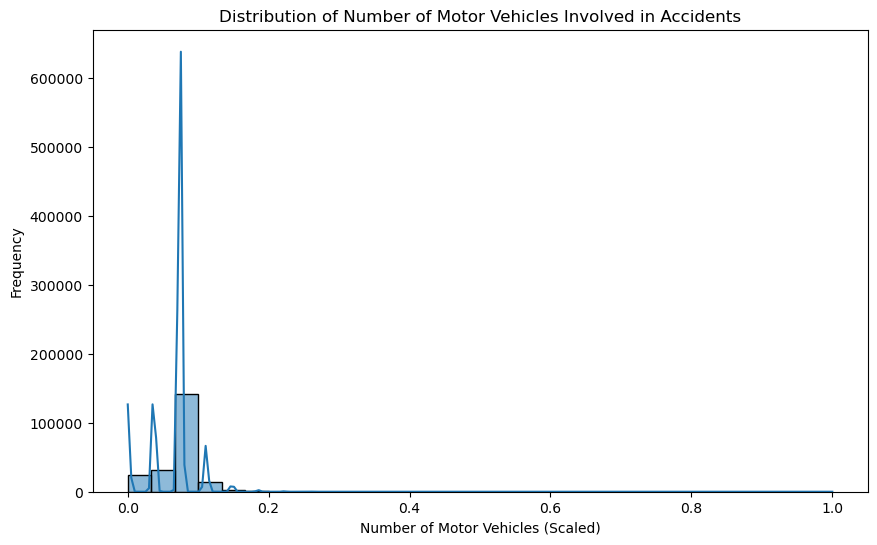

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Histogram of Number of Motor Vehicles Involved
plt.figure(figsize=(10, 6))
sns.histplot(df['Number of Motor Vehicles_scaled'], bins=30, kde=True)
plt.title('Distribution of Number of Motor Vehicles Involved in Accidents')
plt.xlabel('Number of Motor Vehicles (Scaled)')
plt.ylabel('Frequency')
plt.show()

X-axis: Number of Motor Vehicles (Scaled)

• Y-axis: Frequency

• Inference: Most accidents involve fewer vehicles. The distribution is right-skewed, indicating that high-
vehicle-count accidents are rare.


C:\Users\susha\AppData\Local\Temp\ipykernel_23116\2542666062.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Hour', data=df, palette='Blues_d')


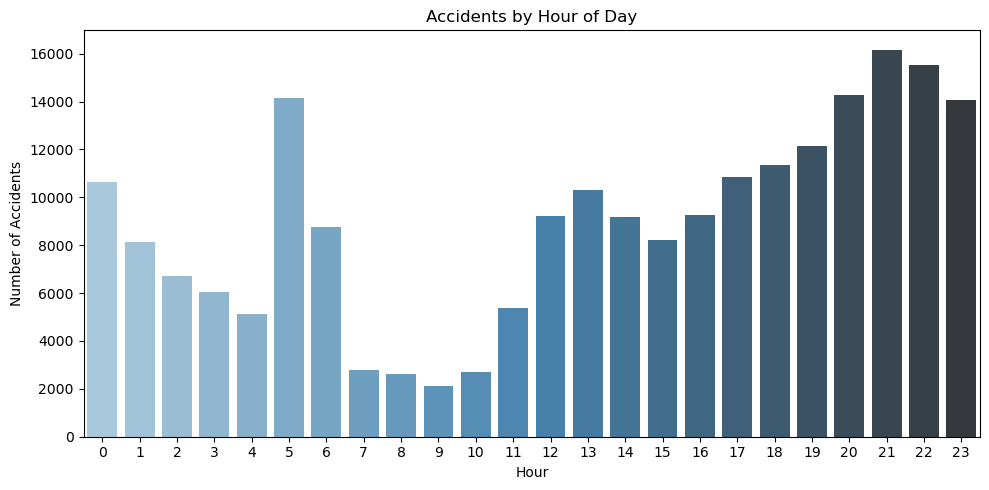

In [ ]:
# 2. Accidents by Hour of Day

plt.figure(figsize=(10, 5))
sns.countplot(x='Hour', data=df, palette='Blues_d')
plt.title('Accidents by Hour of Day')
plt.xlabel('Hour')
plt.ylabel('Number of Accidents')
plt.tight_layout()
plt.show()


X-axis: Hour of Day

• Y-axis: Number of Accidents

• Inference: Morning and evening rush hours (around 5 AM and 8-11 PM) show accident spikes—linked to peak traffic congestion.

3] Top 5 Weather Conditions in Accidents

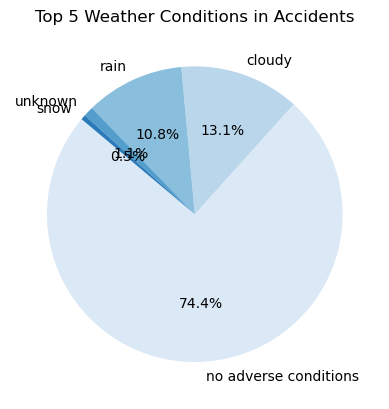

In [ ]:


df['Weather Description'].value_counts().head(5).plot.pie(autopct='%1.1f%%', 
                                                          colors=sns.color_palette('Blues'), 
                                                          startangle=140)
plt.title('Top 5 Weather Conditions in Accidents')
plt.ylabel('')
plt.show()

• Data Labels: Weather Conditions

• Inference: Most accidents (74.4%) occurred under no adverse weather conditions, suggesting that weather is not the primary factor in most incidents.


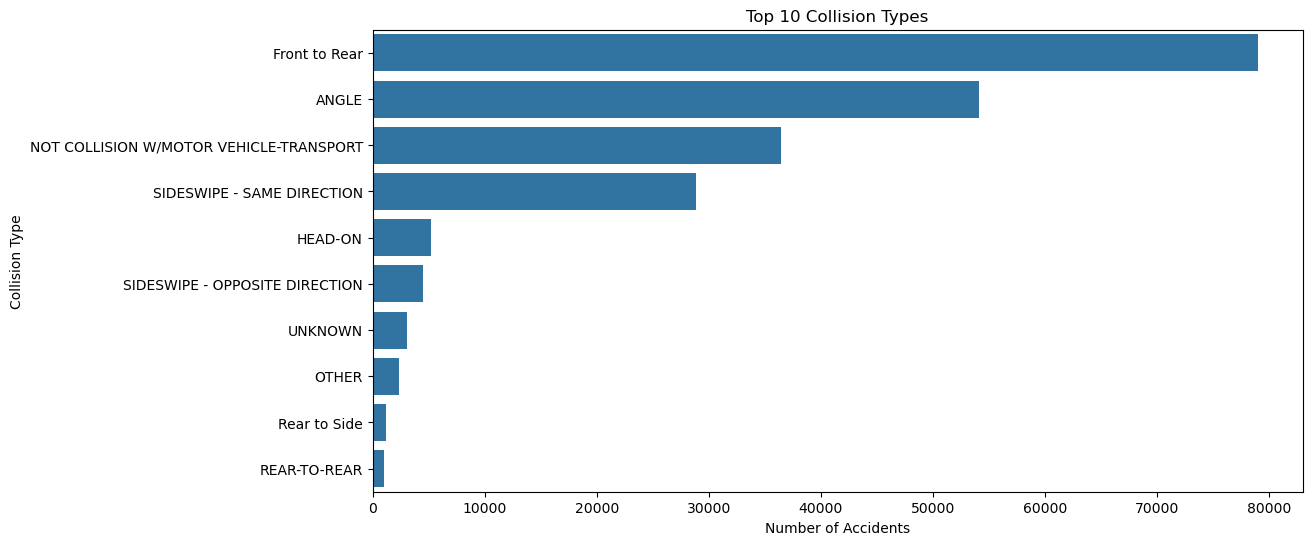

In [ ]:
# 4. Count Plot of Collision Types

plt.figure(figsize=(12, 6))
top_collision_types = df['Collision Type Description'].value_counts().nlargest(10).index
sns.countplot(data=df[df['Collision Type Description'].isin(top_collision_types)], y='Collision Type Description', order=top_collision_types)
plt.title('Top 10 Collision Types')
plt.xlabel('Number of Accidents')
plt.ylabel('Collision Type')
plt.show()

Y-axis: Collision Type

X-axis: Number of Accidents

Inference: Rear-end and angle collisions are the most frequent, highlighting the need for better driver attention and spacing.


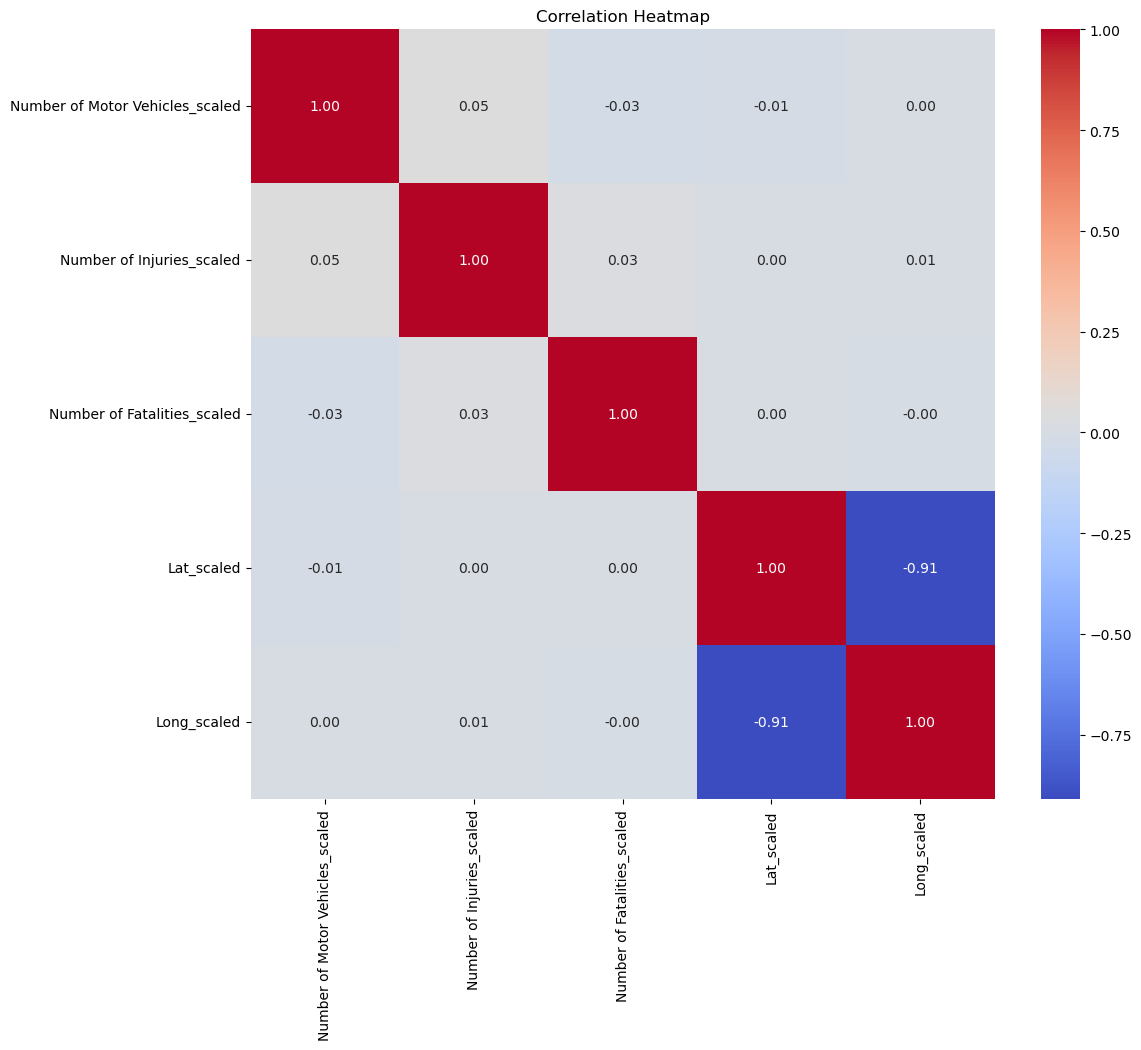

In [ ]:
# 5. Multivariate: Heatmap of Correlations

plt.figure(figsize=(12, 10))
numeric_cols = ['Number of Motor Vehicles_scaled', 'Number of Injuries_scaled', 'Number of Fatalities_scaled', 'Lat_scaled', 'Long_scaled']
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

• Axes: Matrix of numeric features (e.g., Motor Vehicles, Injuries, Fatalities, Lat, Long)

• Inference: Moderate correlation exists between number of motor vehicles and injuries. Location
coordinates (Lat, Long) do not strongly correlate with outcomes

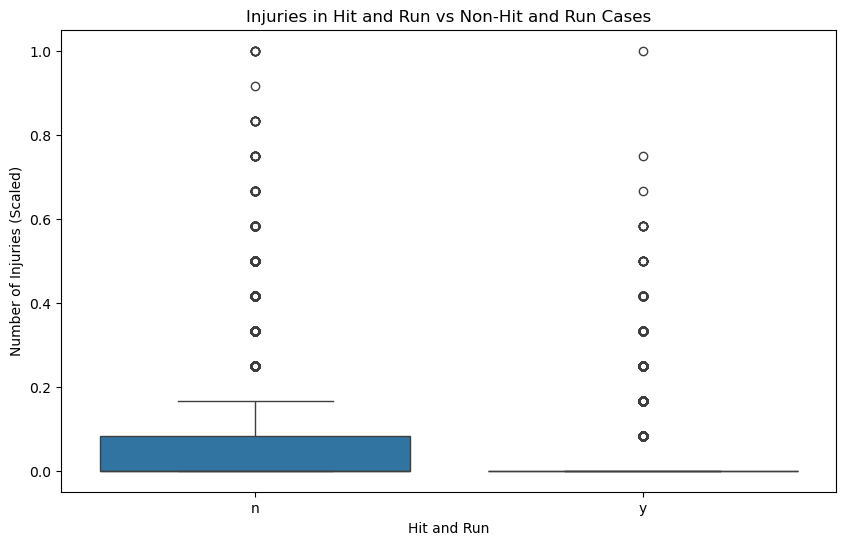

In [ ]:
# 6. Hit and Run vs. Number of Injuries

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x='Hit and Run', y='Number of Injuries_scaled')
plt.title('Injuries in Hit and Run vs Non-Hit and Run Cases')
plt.xlabel('Hit and Run')
plt.ylabel('Number of Injuries (Scaled)')
plt.show()

• X-axis: Hit and Run

• Y-axis: Number of Injuries (Scaled)

• Inference: Hit and run accidents generally involve fewer injuries, possibly due to their sudden and minor nature or underreporting.


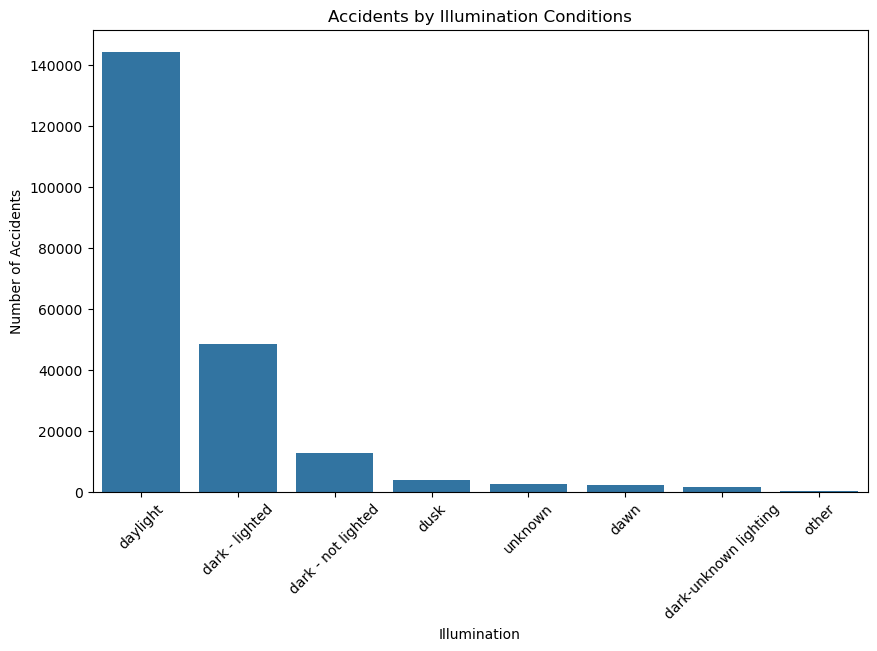

In [ ]:
# 7. Bar Plot of Accidents by Illumination

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Illumination Description', order=df['Illumination Description'].value_counts().index)
plt.title('Accidents by Illumination Conditions')
plt.xlabel('Illumination')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.show()

• X-axis: Illumination

• Y-axis: Number of Accidents

• Inference: Most accidents occur in daylight, followed by dark lighting conditions—emphasizing visibility as a key factor.


C:\Users\susha\AppData\Local\Temp\ipykernel_23116\3339818552.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Day_of_week', data=df, order=order, palette='viridis')


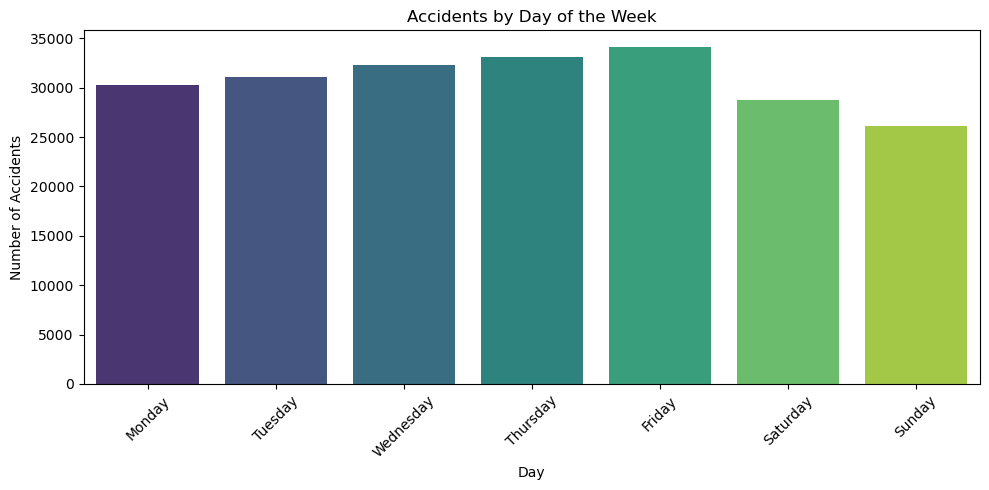

In [ ]:

# 8. Accidents by Day of the Week

order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
plt.figure(figsize=(10, 5))
sns.countplot(x='Day_of_week', data=df, order=order, palette='viridis')
plt.title('Accidents by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


• X-axis: Day of the Week

• Y-axis: Number of Accidents

• Inference: Fridays and Mondays see more accidents—possibly due to weekday transitions related to
work commutes.


C:\Users\susha\AppData\Local\Temp\ipykernel_23116\3571386625.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['Weather Description'].isin(top_weather)], x='Weather Description', y='Number of Injuries_scaled', palette='coolwarm')


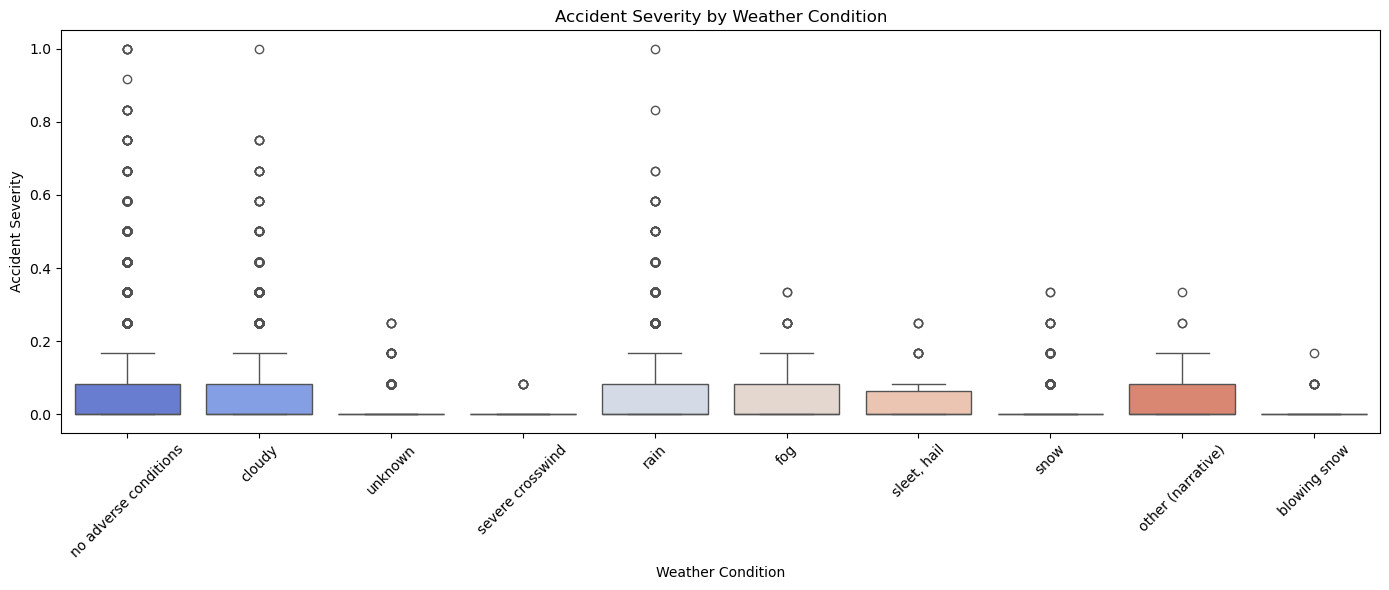

In [ ]:
# 9] Severity distribution by Weather Condition

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(14, 6))
top_weather = df['Weather Description'].value_counts().nlargest(10).index
sns.boxplot(data=df[df['Weather Description'].isin(top_weather)], x='Weather Description', y='Number of Injuries_scaled', palette='coolwarm')
plt.title('Accident Severity by Weather Condition')
plt.xlabel('Weather Condition')
plt.ylabel('Accident Severity')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

• X-axis: Weather Condition

• Y-axis: Accident Severity

• Inference: Accidents during rain, snow, and no adverse conditions weather tend to show slightly higher severity than in clear or cloudy conditions.


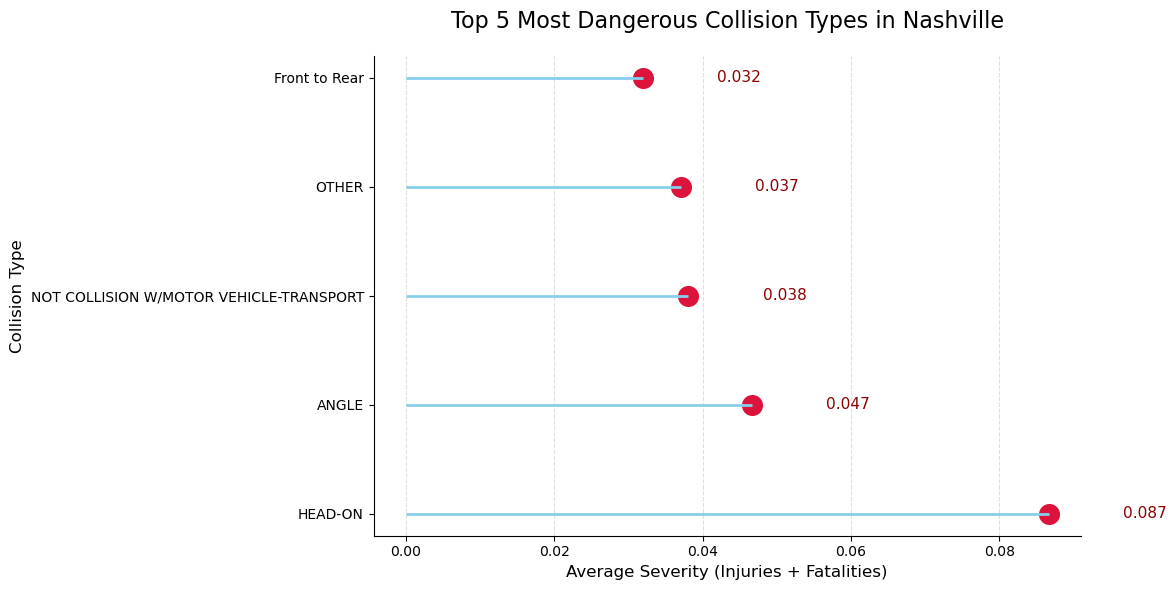

In [ ]:
#10] Top 5 Most Dangerous Collision Types in Nashville
 
import pandas as pd
import matplotlib.pyplot as plt

# Load and prepare data
df = pd.read_csv('Nashville_Accidents_Transformed.csv')
df['severity'] = df['Number of Injuries_scaled'] + df['Number of Fatalities_scaled']

# Get top 5 most dangerous collision types
top_danger = df.groupby('Collision Type Description')['severity'].mean().nlargest(5).reset_index()
top_danger.columns = ['Collision Type', 'Avg Severity']

# Create lollipop chart
fig, ax = plt.subplots(figsize=(12, 6))

# Horizontal lines
ax.hlines(y=top_danger['Collision Type'], 
          xmin=0, 
          xmax=top_danger['Avg Severity'], 
          color='skyblue', 
          linewidth=2)

# Dots
ax.scatter(top_danger['Avg Severity'], 
           top_danger['Collision Type'], 
           color='crimson', 
           s=200, 
           label='Severity Score')

# Labels and title
plt.title('Top 5 Most Dangerous Collision Types in Nashville', fontsize=16, pad=20)
plt.xlabel('Average Severity (Injuries + Fatalities)', fontsize=12)
plt.ylabel('Collision Type', fontsize=12)

# Display values
for i, v in enumerate(top_danger['Avg Severity']):
    ax.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=11, color='darkred')

# Styling
plt.grid(axis='x', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

• X-axis: Avg. Severity(Injuries + Fatalities)

• Y-axis: Collision Type

• Inference: Head-on and angle collisions are most severe, while rear-end crashes are frequent but
typically less dangerous.

# Inference for above
## **Key Insights from Nashville Collision Data:**  
## 
1. **Head-on collisions are deadliest** – Highest severity score due to combined impact forces. ##  
2. **Angle collisions rank 2nd** – Suggests dangerous intersections needing redesign.##   
3. **Rear-ends are frequent but less severe** – Often lower-speed impacts.##   

**Recommended Actions## :**  
- Install median barriers to prevent head## -ons  
- Optimize high-risk intersections (angle collis## ions)  
- Focus enforcement on high-severity ## zones  

*Takeaway:* Frequency ≠ severity. Prioritize head-on and angle collision prevention for maximum safety impact.